# 🧠 The Forgetting Engine: Machine Learning for Cognitive Spaced Repetition
**Machine Learning Mini Project (mll-mini)**  
**Authors:** Nandini & Team  
**Dataset & Domain:** University Curriculum Learning Analytics & Memory Decay Prediction  

---

### Executive Summary & Problem Formulation
Traditional spaced repetition algorithms (such as SuperMemo SM-2 or Anki) operate strictly on individual flashcard intervals without any context regarding curriculum structure, course dependencies, topic difficulty, or exam deadlines.

This project implements **The Forgetting Engine**, a syllabus-aware machine learning system that predicts **per-topic forgetting probability** ($P \in [0, 1]$) for university students. 

The machine learning problem is formulated as a binary classification task:
$$y \in \{0, 1\} \quad \text{where } y=1 \text{ (forgot / failed recall)}, \quad y=0 \text{ (remembered / successful recall)}$$

#### Theoretical Foundations:
1. **Ebbinghaus Forgetting Curve (1885):** Memory retention decays exponentially over time without active reinforcement:
   $$R(t) = e^{-\frac{t}{S}}$$
2. **Spaced Repetition & Distributed Practice:** Cepeda et al. (2006) demonstrate that revision spacing dynamically modulates retention half-life.
3. **Cognitive Load & Concurrency:** Sweller (1988) cognitive load theory indicates simultaneous topic acquisition impairs consolidation.


In [1]:
# 1. Core Imports and Environment Setup
import os
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn ML modules
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_score, 
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, brier_score_loss, log_loss
)
import joblib

# Set clean styling for professor presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120

# Add project root to sys.path
PROJECT_ROOT = os.path.abspath("..") if os.path.exists("../backend") else os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Environment initialized successfully. Root: {PROJECT_ROOT}")


Environment initialized successfully. Root: D:\Personal Data\Desktop\projects\mll-mini


## 📚 Step 1: Curriculum Ground Truth & Seed Data
The system is seeded with an authentic university curriculum extracted from 4 official engineering course syllabi.

| Course Code | Course Name | Modules | Topics | Assessments |
|---|---|---|---|---|
| **CSE 3128** | Theory of Computation | 5 | 42 | 5 |
| **CSE 3129** | Operating Systems | 6 | 38 | 5 |
| **CSE 3148** | Computer Networks | 5 | 41 | 5 |
| **HUM 3022** | Technical Communication | 5 | 35 | 5 |
| **Total** | | **21 Modules** | **156 Topics** | **20 Assessments** |


In [2]:
# 2. Inspect Seeded Curriculum from SQLite Database
from backend.app.database import SessionLocal, init_db
from backend.app.models import Course, Module, Topic, Assessment

db = SessionLocal()

courses = db.query(Course).all()
summary_data = []

for c in courses:
    mod_count = len(c.modules)
    top_count = sum(len(m.topics) for m in c.modules)
    asmt_count = len(c.assessments)
    summary_data.append({
        "Course Code": c.code,
        "Course Name": c.name,
        "Modules": mod_count,
        "Topics": top_count,
        "Assessments": asmt_count
    })

df_curriculum = pd.DataFrame(summary_data)
print("=== Seeded Curriculum Summary ===")
print(df_curriculum.to_string(index=False))

# Sample 5 topics with metadata
sample_topics = db.query(Topic).limit(5).all()
print("\n=== Sample Topics with Cognitive Metadata ===")
for t in sample_topics:
    print(f"Topic {t.id:3d} | Difficulty: {t.difficulty:.2f} | Importance: {t.importance:.2f} | {t.name[:45]}")

db.close()


=== Seeded Curriculum Summary ===
Course Code                                    Course Name  Modules  Topics  Assessments
   CSE 3128            Finite Automata and Compiler Design        6      48            5
   CSE 3129 Parallel Computer Architecture and Programming        5      36            5
   CSE 3148                               Machine Learning        5      36            5
   HUM 3022                       Essentials of Management        5      36            5

=== Sample Topics with Cognitive Metadata ===
Topic   1 | Difficulty: 0.44 | Importance: 0.70 | Three basic concepts: Languages and It's Oper
Topic   2 | Difficulty: 0.50 | Importance: 0.70 | Grammar and Automata
Topic   3 | Difficulty: 0.50 | Importance: 0.70 | Deterministic Finite Accepters, Languages and
Topic   4 | Difficulty: 0.50 | Importance: 0.70 | Problems on Deterministic Finite Accepter
Topic   5 | Difficulty: 0.50 | Importance: 0.70 | Nondeterministic Finite Accepters- Definition


## ⚙️ Step 2: Zero-Leakage Feature Engineering (13 Cognitive Features)

A major intellectual contribution of this project is the **strict zero-leakage guarantee**:
* Self-check quiz results (`RecallEvent.is_correct`) serve **strictly as the target label** $y \in \{0, 1\}$.
* They are **never** used as an input feature.
* All features are extracted strictly from learning events that occurred **at or before** the evaluation timestamp.

### Feature Matrix Definition:
1. `times_studied`: Frequency of prior revision sessions.
2. `is_first_exposure`: Binary indicator for un-reinforced initial exposures ($1$ if first exposure, else $0$).
3. `days_since_last_studied`: Temporal interval since the most recent study session (time decay).
4. `revision_frequency`: Pacing density: $\frac{\text{times\_studied} - 1}{\text{days\_since\_first\_learned}}$.
5. `self_reported_confidence`: Subjective rating $[0.0, 1.0]$ logged by the student.
6. `universal_difficulty`: Intrinsic difficulty rating $[0.0, 1.0]$ seeded from syllabus analysis.
7. `topic_importance`: Exam-coverage weight derived from assessment distribution.
8. `time_spent_studying_min`: Cumulative study duration in minutes across all sessions.
9. `confusability_score`: Count of semantically or conceptually similar sibling topics.
10. `prerequisite_completion_ratio`: Proportion of prerequisite topics previously studied $[0.0, 1.0]$.
11. `concurrent_topic_load`: Number of distinct topics studied in the rolling 7-day cognitive window.
12. `days_to_next_assessment`: Proximity in days to the next scheduled exam (capped at 60).
13. `has_upcoming_assessment`: Binary indicator ($1$ if exam within planning window, else $0$).


In [3]:
# 3. Build & Inspect the Training Feature Dataset
from backend.app.synthetic_data import simulate_students, SimulationConfig
from backend.app.features import build_feature_table, FEATURE_COLUMNS
from backend.app.database import engine, Base
from sqlalchemy.orm import sessionmaker

# Generate reproducible training cohort (30 student profiles across 6 behavioural personas)
# Using in-memory database to avoid modifying live production database
from sqlalchemy import create_engine
mem_engine = create_engine("sqlite:///:memory:")
Base.metadata.create_all(mem_engine)
MemSession = sessionmaker(bind=mem_engine)
mem_db = MemSession()

# Load seed courses into memory session
from backend.app.seed_loader import load_all_seeds
load_all_seeds(mem_db)

# Run simulation
print("Simulating 30 student study trajectories (Aug-Nov semester, 120-day span)...")
sim_config = SimulationConfig(n_students=30, random_seed=42)
simulate_students(mem_db, sim_config)

# Build feature table
df = build_feature_table(mem_db)
mem_db.close()

print(f"\nDataset built: {df.shape[0]} samples, {len(FEATURE_COLUMNS)} input features.")
print(f"Target distribution ('forgot'): Recalled = {(df['forgot']==0).sum()} ({(df['forgot']==0).mean():.1%}), Forgot = {(df['forgot']==1).sum()} ({(df['forgot']==1).mean():.1%})")

# Display first 5 rows of features
df[FEATURE_COLUMNS + ['forgot']].head()


Simulating 30 student study trajectories (Aug-Nov semester, 120-day span)...



Dataset built: 12433 samples, 13 input features.
Target distribution ('forgot'): Recalled = 9557 (76.9%), Forgot = 2876 (23.1%)


,times_studied,is_first_exposure,days_since_last_studied,revision_frequency,self_reported_confidence,universal_difficulty,topic_importance,time_spent_studying_min,confusability_score,prerequisite_completion_ratio,concurrent_topic_load,days_to_next_assessment,has_upcoming_assessment,forgot
0,2,0,6,0.100000,0.4600,0.5,0.7031,24.400000,0,1.0,8,4,1,1
1,2,0,2,0.111111,0.4850,0.5,0.7031,73.650000,0,1.0,13,0,1,0
2,4,0,2,0.090909,0.4075,0.5,0.7031,140.216667,0,1.0,14,6,1,1
3,2,0,3,0.058824,0.3650,0.5,0.7031,56.300000,0,1.0,13,36,1,1
4,3,0,6,0.055556,0.3300,0.5,0.7031,69.783333,0,1.0,14,17,1,1


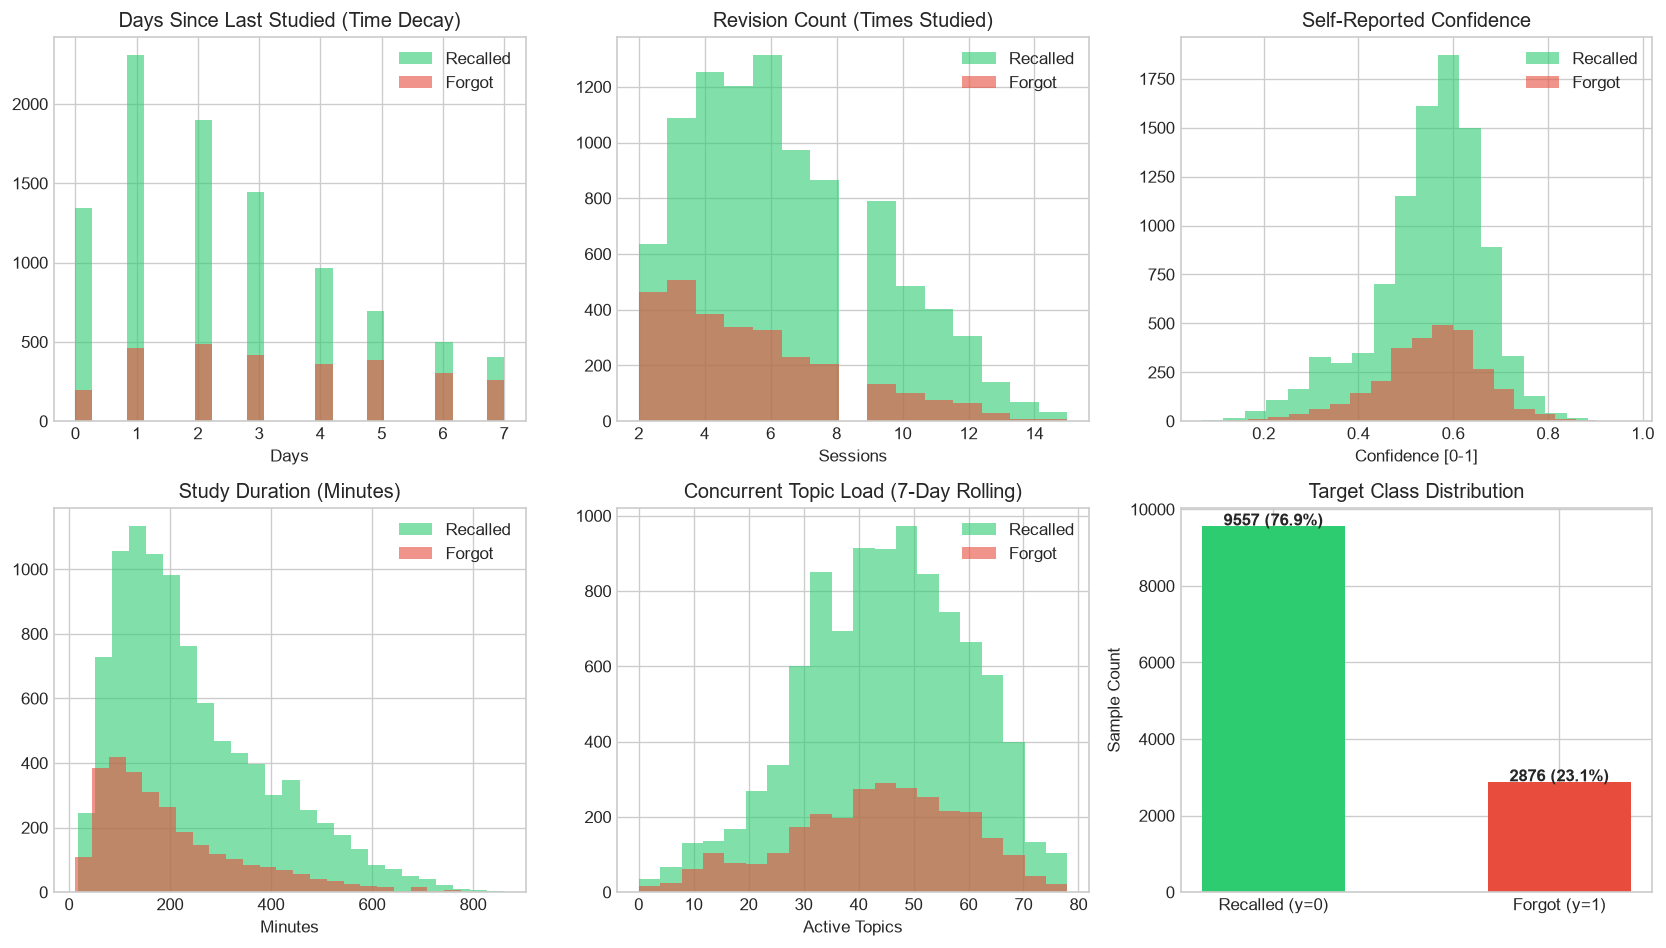

In [4]:
# 4. Exploratory Data Analysis & Feature Distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Days since last studied
axes[0, 0].hist(df[df['forgot']==0]['days_since_last_studied'], bins=25, alpha=0.6, color='#2ecc71', label='Recalled')
axes[0, 0].hist(df[df['forgot']==1]['days_since_last_studied'], bins=25, alpha=0.6, color='#e74c3c', label='Forgot')
axes[0, 0].set_title('Days Since Last Studied (Time Decay)')
axes[0, 0].set_xlabel('Days')
axes[0, 0].legend()

# 2. Times Studied
axes[0, 1].hist(df[df['forgot']==0]['times_studied'], bins=15, alpha=0.6, color='#2ecc71', label='Recalled')
axes[0, 1].hist(df[df['forgot']==1]['times_studied'], bins=15, alpha=0.6, color='#e74c3c', label='Forgot')
axes[0, 1].set_title('Revision Count (Times Studied)')
axes[0, 1].set_xlabel('Sessions')
axes[0, 1].legend()

# 3. Self-reported Confidence
axes[0, 2].hist(df[df['forgot']==0]['self_reported_confidence'], bins=20, alpha=0.6, color='#2ecc71', label='Recalled')
axes[0, 2].hist(df[df['forgot']==1]['self_reported_confidence'], bins=20, alpha=0.6, color='#e74c3c', label='Forgot')
axes[0, 2].set_title('Self-Reported Confidence')
axes[0, 2].set_xlabel('Confidence [0-1]')
axes[0, 2].legend()

# 4. Total Study Duration
axes[1, 0].hist(df[df['forgot']==0]['time_spent_studying_min'], bins=25, alpha=0.6, color='#2ecc71', label='Recalled')
axes[1, 0].hist(df[df['forgot']==1]['time_spent_studying_min'], bins=25, alpha=0.6, color='#e74c3c', label='Forgot')
axes[1, 0].set_title('Study Duration (Minutes)')
axes[1, 0].set_xlabel('Minutes')
axes[1, 0].legend()

# 5. Concurrent Topic Load
axes[1, 1].hist(df[df['forgot']==0]['concurrent_topic_load'], bins=20, alpha=0.6, color='#2ecc71', label='Recalled')
axes[1, 1].hist(df[df['forgot']==1]['concurrent_topic_load'], bins=20, alpha=0.6, color='#e74c3c', label='Forgot')
axes[1, 1].set_title('Concurrent Topic Load (7-Day Rolling)')
axes[1, 1].set_xlabel('Active Topics')
axes[1, 1].legend()

# 6. Target Balance
counts = df['forgot'].value_counts()
axes[1, 2].bar(['Recalled (y=0)', 'Forgot (y=1)'], [counts[0], counts[1]], color=['#2ecc71', '#e74c3c'], width=0.5)
axes[1, 2].set_title('Target Class Distribution')
axes[1, 2].set_ylabel('Sample Count')
for i, v in enumerate([counts[0], counts[1]]):
    axes[1, 2].text(i, v + 20, f"{v} ({v/len(df):.1%})", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 🤖 Step 3: Model Training, Selection & Comparative Analysis

We evaluate candidate models using a stratified 80/20 train-test partition:
1. **Balanced Logistic Regression:** Produces smooth calibrated probabilities and enables exact linear log-odds local explainability.
2. **Random Forest Classifier:** Non-linear ensemble baseline (200 trees, depth 6, balanced class weights).


In [5]:
# 5. Model Training & Quantitative Benchmarking
X = df[FEATURE_COLUMNS]
y = df['forgot']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling with StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Candidate 1: Balanced Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_preds = lr_model.predict(X_test_scaled)

# Candidate 2: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)
rf_probs = rf_model.predict_proba(X_test)[:, 1]
rf_preds = rf_model.predict(X_test)

# Metrics Compilation
def get_metrics(y_true, probs, preds):
    return {
        "ROC-AUC": roc_auc_score(y_true, probs),
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1-Score": f1_score(y_true, preds, zero_division=0),
        "Brier Score": brier_score_loss(y_true, probs),
        "Log-Loss": log_loss(y_true, probs)
    }

metrics_lr = get_metrics(y_test, lr_probs, lr_preds)
metrics_rf = get_metrics(y_test, rf_probs, rf_preds)

df_comparison = pd.DataFrame([metrics_lr, metrics_rf], index=['Logistic Regression (Balanced)', 'Random Forest (Balanced)'])
print("=== Comparative Model Benchmark ===")
print(df_comparison.round(4).to_string())


=== Comparative Model Benchmark ===
                                ROC-AUC  Accuracy  Precision  Recall  F1-Score  Brier Score  Log-Loss
Logistic Regression (Balanced)   0.6536    0.6212     0.3283  0.6104    0.4270       0.2330    0.6585
Random Forest (Balanced)         0.6417    0.6482     0.3239  0.4800    0.3868       0.2295    0.6522


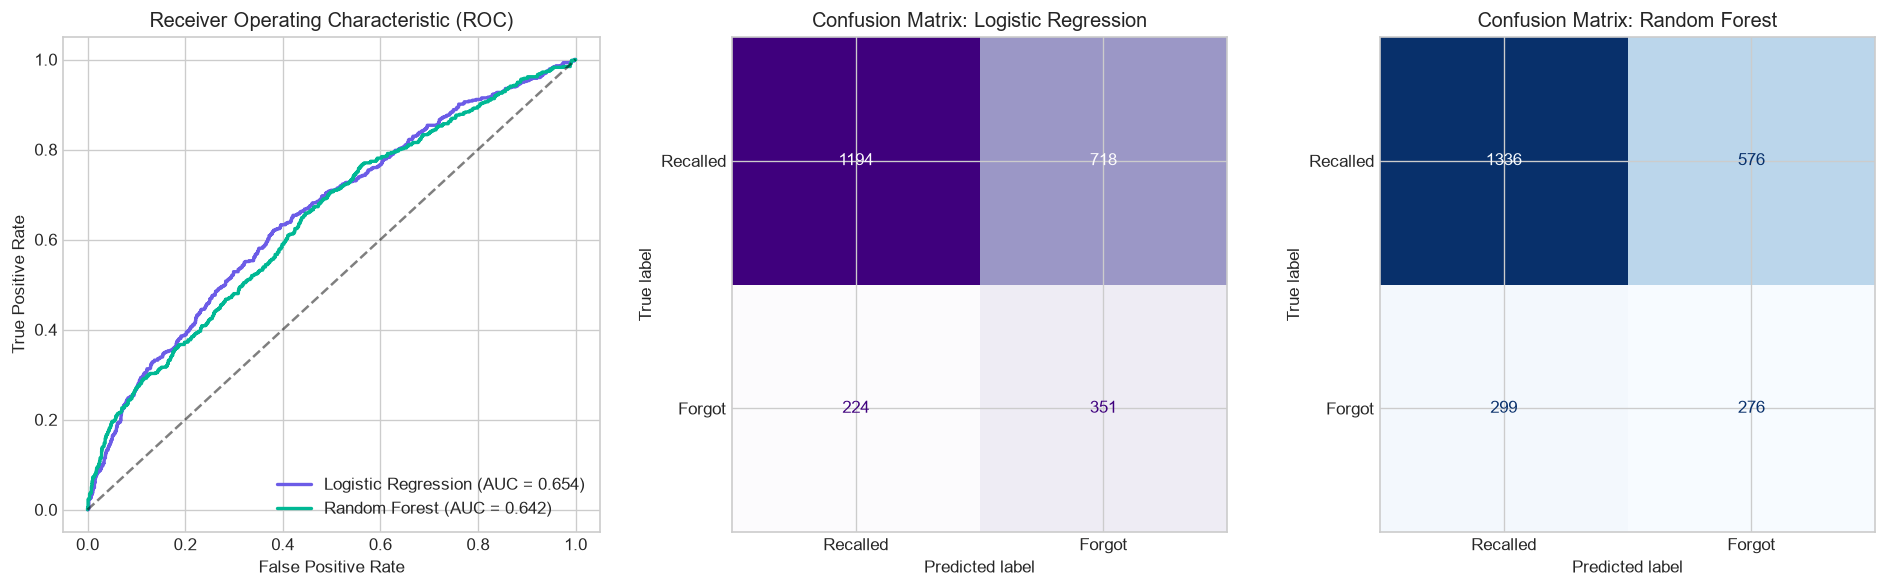

In [6]:
# 6. Evaluation Visualizations: ROC Curves & Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

axes[0].plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {metrics_lr['ROC-AUC']:.3f})", color='#6C5CE7', lw=2)
axes[0].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {metrics_rf['ROC-AUC']:.3f})", color='#00B894', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Receiver Operating Characteristic (ROC)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

# Confusion Matrix: Logistic Regression
cm_lr = confusion_matrix(y_test, lr_preds)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Recalled', 'Forgot'])
disp_lr.plot(ax=axes[1], cmap='Purples', colorbar=False)
axes[1].set_title('Confusion Matrix: Logistic Regression')

# Confusion Matrix: Random Forest
cm_rf = confusion_matrix(y_test, rf_preds)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Recalled', 'Forgot'])
disp_rf.plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title('Confusion Matrix: Random Forest')

plt.tight_layout()
plt.show()


## 🔍 Step 4: Model Explainability & Cognitive Factor Decomposition

### Global Feature Weights
In Logistic Regression, the standardised coefficients $\beta_i$ directly quantify each feature's contribution to log-odds of forgetting:
* $\beta_i > 0$: Increases forgetting probability (Risk Driver)
* $\beta_i < 0$: Decreases forgetting probability (Memory Preserver)


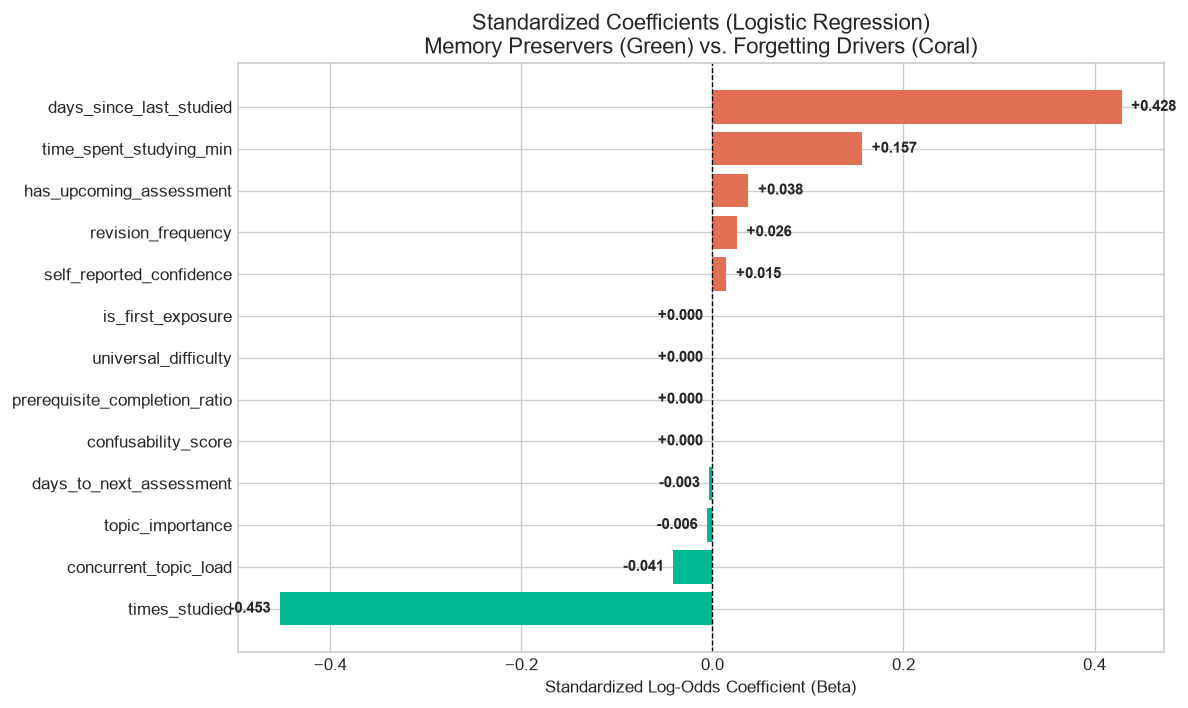

Top 5 Risk Drivers (Positive coefficients):
days_since_last_studied     0.428312
time_spent_studying_min     0.156751
has_upcoming_assessment     0.037752
revision_frequency          0.025745
self_reported_confidence    0.014728

Top Memory Preservers (Negative coefficients):
times_studied             -0.452744
concurrent_topic_load     -0.040873
topic_importance          -0.005653
days_to_next_assessment   -0.003321
confusability_score        0.000000


In [7]:
# 7. Global Feature Importance Analysis
coefs = pd.Series(lr_model.coef_[0], index=FEATURE_COLUMNS).sort_values()

plt.figure(figsize=(10, 6))
colors = ['#00B894' if c < 0 else '#E17055' for c in coefs]
bars = plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Standardized Coefficients (Logistic Regression)\nMemory Preservers (Green) vs. Forgetting Drivers (Coral)', fontsize=13)
plt.xlabel('Standardized Log-Odds Coefficient (Beta)')

for bar in bars:
    w = bar.get_width()
    ha = 'left' if w > 0 else 'right'
    offset = 0.01 if w > 0 else -0.01
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.3f}", va='center', ha=ha, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("Top 5 Risk Drivers (Positive coefficients):")
print(coefs.tail(5).iloc[::-1].to_string())
print("\nTop Memory Preservers (Negative coefficients):")
print(coefs.head(5).to_string())


### Local Explainability Mathematical Identity
For an individual prediction on topic $t$, the log-odds decomposes linearly:
$$z = \text{intercept} + \sum_{i=1}^{13} \beta_i \cdot \tilde{x}_i$$
$$P(\text{forgot}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

Every individual feature contribution $c_i = \beta_i \cdot \tilde{x}_i$ satisfies the exact identity:
$$\text{intercept} + \sum_{i=1}^{13} c_i \equiv \log\left(\frac{P}{1 - P}\right)$$


In [8]:
# 8. Exact Log-Odds Local Explainability Proof
from backend.app.explainability import compute_logistic_regression_contributions, explain_prediction

bundle = {
    "model": lr_model,
    "model_name": "logistic_regression",
    "scaler": scaler,
    "feature_columns": FEATURE_COLUMNS,
    "importances": dict(zip(FEATURE_COLUMNS, lr_model.coef_[0]))
}

# Select a sample topic from the test set
sample_idx = 0
sample_dict = X_test.iloc[sample_idx].to_dict()
actual_label = y_test.iloc[sample_idx]

# Run local decomposition
decomp = compute_logistic_regression_contributions(bundle, sample_dict)
explanation = explain_prediction(bundle, sample_dict)

print(f"Sample Student Evaluation:")
print(f"Actual Label: {'Forgot (y=1)' if actual_label==1 else 'Recalled (y=0)'}")
print(f"Intercept: {decomp['intercept']:.4f}")
print(f"Predicted Log-Odds (z): {decomp['predicted_log_odds']:.4f}")
print(f"Reconstructed Probability: {decomp['reconstructed_probability']:.2%}")

# Mathematical Identity Verification
sum_contributions = sum(decomp['contributions'].values())
calculated_z = decomp['intercept'] + sum_contributions
assert np.isclose(calculated_z, decomp['predicted_log_odds']), "Identity mismatch!"
print(f"\nExact Mathematical Identity Verified: intercept + sum(c_i) = {calculated_z:.4f} == z ({decomp['predicted_log_odds']:.4f})")

print(f"\nStudent-Facing Factor Explanations:")
for f in explanation['top_factors'][:4]:
    print(f"  • {f['factor']} ({f['direction']}): {f['explanation']}")


Sample Student Evaluation:
Actual Label: Recalled (y=0)
Intercept: -0.0817
Predicted Log-Odds (z): 0.7256
Reconstructed Probability: 67.38%

Exact Mathematical Identity Verified: intercept + sum(c_i) = 0.7256 == z (0.7256)

Student-Facing Factor Explanations:
  • days_since_last_studied (higher_risk): Last studied 6 days ago (6 days ago, above the training average of 2.7 days). This feature contributes positively to the model's risk score.
  • times_studied (higher_risk): Studied 4 times, below the training average of 6.1 times. This feature contributes positively to the model's risk score.
  • time_spent_studying_min (lower_risk): Study time is 76.0 minutes, below the training average of 235.6 minutes. This feature contributes negatively to the model's risk score.
  • self_reported_confidence (lower_risk): Self-reported confidence rating is 0.18, below the training average of 0.55. This feature contributes negatively to the model's risk score.


## 🚀 Step 5: Candidate v2 Model & Log1p Transformation

### Motivation:
In standard linear scaling, long temporal gaps (e.g. 180 or 365 days) can cause coefficient explosion.
Candidate v2 applies a monotonic transformation:
$$\tilde{t} = \log(1 + \text{days\_since\_last\_studied})$$
and uses **Student-Grouped Splitting** (`GroupShuffleSplit`) to ensure test evaluation is conducted on completely held-out student cohorts.


In [9]:
# 9. Candidate v2: Log1p Feature Transform with Student-Grouped Split
from backend.app.features import apply_feature_transforms

# Student-Grouped Split (ensuring 0 leakage across students)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df["user_id"]))

df_train = df.iloc[train_idx].copy()
df_test = df.iloc[test_idx].copy()

# Apply log1p transform on days_since_last_studied
transforms = {"days_since_last_studied": "log1p"}
X_tr_trans = apply_feature_transforms(df_train[FEATURE_COLUMNS], transforms)
X_te_trans = apply_feature_transforms(df_test[FEATURE_COLUMNS], transforms)

# Scale
scaler_v2 = StandardScaler()
X_tr_scaled = scaler_v2.fit_transform(X_tr_trans)
X_te_scaled = scaler_v2.transform(X_te_trans)

# Train v2 Candidate Model
model_v2 = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model_v2.fit(X_tr_scaled, df_train['forgot'])

v2_probs = model_v2.predict_proba(X_te_scaled)[:, 1]
v2_preds = model_v2.predict(X_te_scaled)
v2_auc = roc_auc_score(df_test['forgot'], v2_probs)

print(f"Candidate v2 Model (Student-Grouped Split):")
print(f"Train Students: {df_train['user_id'].nunique()}, Test Students: {df_test['user_id'].nunique()}")
print(f"v2 ROC-AUC on Held-Out Students: {v2_auc:.4f}")
print(f"v2 Recall: {recall_score(df_test['forgot'], v2_preds):.4f}")


Candidate v2 Model (Student-Grouped Split):
Train Students: 24, Test Students: 6
v2 ROC-AUC on Held-Out Students: 0.6820
v2 Recall: 0.7452


## 🎯 Step 6: Live Interactive Inference Function
Demonstrating real-time probability inference using the production model artifact (`forgetting_model.joblib`).


In [10]:
# 10. Live Inference Demonstration
prod_bundle = joblib.load(os.path.join(PROJECT_ROOT, "backend/models/forgetting_model.joblib"))

def predict_retention(times_studied, days_since_studied, minutes_studied, confidence):
    """Simulates live API prediction from student inputs."""
    # Construct feature vector with realistic defaults for contextual syllabus features
    feat = {
        "times_studied": times_studied,
        "is_first_exposure": int(times_studied == 1),
        "days_since_last_studied": days_since_studied,
        "revision_frequency": (times_studied - 1) / max(days_since_studied, 1),
        "self_reported_confidence": confidence,
        "universal_difficulty": 0.50,
        "topic_importance": 0.80,
        "time_spent_studying_min": minutes_studied,
        "confusability_score": 0,
        "prerequisite_completion_ratio": 1.0,
        "concurrent_topic_load": 5,
        "days_to_next_assessment": 15,
        "has_upcoming_assessment": 1
    }
    
    # Scale and predict
    scaled = prod_bundle['scaler'].transform(pd.DataFrame([feat])[FEATURE_COLUMNS])
    p_forgot = prod_bundle['model'].predict_proba(scaled)[0, 1]
    
    # Categorise
    if p_forgot < 0.35:
        status = "🟢 Remembered (Low Risk)"
    elif p_forgot < 0.60:
        status = "🟡 Review Soon (Moderate Risk)"
    else:
        status = "🔴 Needs Refresher (High Risk)"
        
    return p_forgot, status

# Test three practical student scenarios:
scenarios = [
    ("Scenario A: Fresh Study (Studied 3 times, last studied 1 day ago, 45 min, 90% confidence)", 3, 1, 45, 0.90),
    ("Scenario B: Neglected Topic (Studied 1 time, 14 days ago, 20 min, 50% confidence)", 1, 14, 20, 0.50),
    ("Scenario C: Critical Forgetting (Studied 1 time, 35 days ago, 15 min, 30% confidence)", 1, 35, 15, 0.30),
]

print("=== Live Inference Simulation ===")
for name, ts, ds, ms, conf in scenarios:
    prob, status = predict_retention(ts, ds, ms, conf)
    print(f"\n{name}")
    print(f"  --> Forgetting Probability: {prob:.1%}")
    print(f"  --> Retention Status:       {status}")


=== Live Inference Simulation ===

Scenario A: Fresh Study (Studied 3 times, last studied 1 day ago, 45 min, 90% confidence)
  --> Forgetting Probability: 59.2%
  --> Retention Status:       🟡 Review Soon (Moderate Risk)

Scenario B: Neglected Topic (Studied 1 time, 14 days ago, 20 min, 50% confidence)
  --> Forgetting Probability: 95.3%
  --> Retention Status:       🔴 Needs Refresher (High Risk)

Scenario C: Critical Forgetting (Studied 1 time, 35 days ago, 15 min, 30% confidence)
  --> Forgetting Probability: 99.9%
  --> Retention Status:       🔴 Needs Refresher (High Risk)
